# 13 · Tuning XGBoost & CatBoost + Lebih Banyak Seed

Dua pengungkit yang **belum pernah** dipakai pada anggota ensemble selain LightGBM:

**1. Regularisasi kuat untuk XGBoost & CatBoost.** LightGBM naik ± 0,003 setelah dibuat sangat sederhana (7 daun, ≥ 600 baris per daun, 30% kolom per pohon). XGBoost (`max_depth 4`, `min_child_weight 20`) dan CatBoost (`depth 6` = 64 daun) masih memakai parameter awal notebook 07, jauh lebih "bebas" daripada LightGBM. Di data yang halus dan hampir aditif seperti ini, pohon yang lebih sederhana biasanya lebih baik.

| Konfigurasi | Isi |
|---|---|
| `xgb_d3` | kedalaman 3, `min_child_weight` 50, 30% kolom, λ 10, lr 0,03 |
| `xgb_l7` | 7 daun (`lossguide`, meniru LightGBM), `min_child_weight` 70, 30% kolom, λ 10, lr 0,03 |
| `xgb_d2` | kedalaman 2 (hanya interaksi 2 fitur), `min_child_weight` 50, 30% kolom, λ 10, lr 0,05 |
| `xgb_d3_kuat` | kedalaman 3, `min_child_weight` 100, 30% kolom, λ 30, lr 0,03 |
| `cat_d4` | kedalaman 4 (16 daun), sisanya sama dengan `cat_v1` |
| `cat_d4_kuat` | kedalaman 4, `l2_leaf_reg` 30, 30% kolom |
| `cat_l7` | 7 daun (`Lossguide`), ≥ 600 baris per daun, 30% kolom |
| `cat_d6_kuat` | kedalaman 6 tetap, `l2_leaf_reg` 30, 30% kolom |
| `cat_d6_sangat_kuat` | kedalaman 6, `l2_leaf_reg` 60, 30% kolom, lr 0,03 |

> Dua konfigurasi CatBoost kedalaman 6 saya tambahkan setelah penyaringan awal di data sampel: mengurangi kedalaman **saja** tidak membantu CatBoost (`cat_d4` −0,0008, `cat_d3` −0,0004), tapi regularisasi L2 + kolom lebih sedikit membantu. Karena grid ini ikut dibentuk oleh hasil, konfirmasi di seed baru (tahap B) makin penting.

**2. Lebih banyak seed per anggota (3 → 10).** Model kita sangat bervariasi antar seed: LightGBM per seed 0,5208, rata-rata 3 seed 0,5238. Menambah seed adalah perataan murni, jadi secara teori **tidak bisa merugikan** (dalam ekspektasi). Karena itu pengungkit ini **tidak perlu lolos ambang 0,002**. Yang diukur hanya seberapa besar manfaatnya.

**Protokol (seperti notebook 06):**
- **Tahap A (seed 42, 7, 2024):** 9 konfigurasi dibandingkan berpasangan dengan `xgb_v1` / `cat_v1`.
- **Tahap B (konfirmasi di 2 seed baru: 11, 99):** konfigurasi terbaik per model **dan** versi v1-nya dilatih di 2 seed yang belum pernah dipakai untuk memilih, lalu diputuskan dengan 5 seed. Ini meredam bias "memilih yang terbaik dari 4 di data yang sama".
  - jelas: Δ ≥ 0,005, semua seed naik · tipis: Δ ≥ 0,002, semua seed naik · selain itu: tetap v1
- **Tahap C:** keempat anggota (versi terpilih) diperluas sampai 10 seed.
- **Tahap D:** ensemble dinilai (1) efek tuning, berpasangan per seed; (2) efek jumlah seed, dengan kurva KS terhadap jumlah seed.

**Waktu (CPU):** di mesin saya (2 core), XGBoost ± 6–7 menit per seed dan CatBoost ± 3–5 menit per seed. Seluruh notebook ± 3,5–4 jam, atau ± 2,5 jam dengan `QUICK = True`. Setiap run **langsung disimpan** (`SKIP_DONE = True`), jadi notebook boleh dihentikan lalu dijalankan ulang kapan saja; run yang sudah ada dimuat dari disk. `QUICK = True` hanya menguji 2 konfigurasi per model di tahap A (yang terbaik di data sampel saya).

In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import eda_utils as E
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(70)

meta = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
FEAT, CATS = meta["features"], meta["categorical"]
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()

SEEDS_A = (42, 7, 2024)                                   # tahap A (sama dengan anggota yang sudah ada)
SEEDS_B = (11, 99)                                        # tahap B: konfirmasi di seed baru
SEEDS_10 = (42, 7, 2024, 11, 99, 123, 2025, 31, 77, 555)  # tahap C
SKIP_DONE = True
QUICK = False

V1 = {"lgbm": M.run_from_disk("lgbm_tuned", y), "xgb": M.run_from_disk("xgb_v1", y),
      "cat": M.run_from_disk("cat_v1", y), "logreg": M.run_from_disk("logreg_v1", y)}
P_LGB = {k: v for k, v in V1["lgbm"]["params"].items() if k != "random_state"}
for k, r in V1.items():
    print(f"{k:7s} seed tersimpan: {r['seeds']}")
print(f"e-commerce: {meta['ecommerce_source']}")

lgbm    seed tersimpan: [42, 7, 2024, 11, 99]
xgb     seed tersimpan: [42, 7, 2024]
cat     seed tersimpan: [42, 7, 2024]
logreg  seed tersimpan: [42, 7, 2024]
e-commerce: ecommerce_transactions.csv


In [3]:
def run_cached(name, kind, seeds, params=None):
    """Latih (atau muat dari disk) satu run. kind: lgbm / xgb / cat / logreg."""
    if SKIP_DONE and (M.PRED_DIR / f"{name}_meta.json").exists():
        return M.run_from_disk(name, y)
    t = time.time()
    if kind == "lgbm":
        r = M.train_lgb_cv(train, test, FEAT, CATS, seeds=seeds, params=params, verbose=False)
    else:
        r = M.train_cv(kind, train, test, FEAT, CATS, seeds=seeds, params=params, verbose=False)
    mins = round((time.time() - t) / 60, 1)
    M.save_run(name, train, test, r, extra=dict(kind=kind, feature_version="v1", minutes=mins, tuning_params=params or {}))
    print(f"  {name}: seed {list(seeds)} selesai dalam {mins} menit", flush=True)
    return M.run_from_disk(name, y)


def merge_runs(parts):
    """Gabungkan beberapa run dengan seed BERBEDA menjadi satu run (OOF per seed + prediksi test rata-rata tertimbang)."""
    obs, tp, n = {}, 0.0, 0
    for r in parts:
        for s, o in r["oof_by_seed"].items():
            assert s not in obs, f"seed {s} dobel"
            obs[s] = o
        tp = tp + r["test_pred"] * len(r["seeds"])
        n += len(r["seeds"])
    out = dict(oof_by_seed=obs, seeds=list(obs), test_pred=tp / n, oof=np.mean(list(obs.values()), axis=0),
               features=parts[0]["features"], params=parts[0]["params"], best_iters=[0])
    out["ks_oof"] = M.ks_score(y, out["oof"])
    out["ks_by_seed"] = {s: M.ks_score(y, o) for s, o in obs.items()}
    return out


def cmp_row(name, c, noise=0.0015):
    ns = c["per_seed"].height
    return dict(perbandingan=name, delta_oof_gabungan=c["delta_oof"],
                **{f"d_s{s}": d for s, d in zip(c["per_seed"]["seed"], c["per_seed"]["delta"])},
                delta_rata2=c["delta_seed_mean"], seed_naik=f"{c['n_seed_positive']}/{ns}",
                keputusan=M.verdict(c, noise=noise))

## 1. Tahap A: 9 konfigurasi, 3 seed

In [4]:
CONFIGS = {
    "xgb_d3":      ("xgb", dict(max_depth=3, min_child_weight=50, colsample_bytree=0.3, reg_lambda=10, learning_rate=0.03)),
    "xgb_l7":      ("xgb", dict(grow_policy="lossguide", max_depth=0, max_leaves=7, min_child_weight=70,
                                colsample_bytree=0.3, reg_lambda=10, learning_rate=0.03)),
    "xgb_d2":      ("xgb", dict(max_depth=2, min_child_weight=50, colsample_bytree=0.3, reg_lambda=10, learning_rate=0.05)),
    "xgb_d3_kuat": ("xgb", dict(max_depth=3, min_child_weight=100, colsample_bytree=0.3, reg_lambda=30, learning_rate=0.03)),
    "cat_d4":      ("cat", dict(depth=4)),
    "cat_d4_kuat": ("cat", dict(depth=4, l2_leaf_reg=30, rsm=0.3)),
    "cat_l7":      ("cat", dict(grow_policy="Lossguide", max_leaves=7, min_data_in_leaf=600, rsm=0.3)),
    "cat_d6_kuat": ("cat", dict(l2_leaf_reg=30, rsm=0.3)),
    "cat_d6_sangat_kuat": ("cat", dict(l2_leaf_reg=60, rsm=0.3, learning_rate=0.03)),
}
if QUICK:
    CONFIGS = {k: CONFIGS[k] for k in ("xgb_d3_kuat", "xgb_l7", "cat_d4_kuat", "cat_d6_kuat")}

A = {}
for name, (kind, prm) in CONFIGS.items():
    A[name] = run_cached(f"t13_{name}", kind, SEEDS_A, prm)
rows = []
for name, (kind, _) in CONFIGS.items():
    c = M.compare_runs(V1[kind], A[name], y)
    rows.append(dict(model=kind, konfigurasi=name, ks_rata2_per_seed=np.mean([A[name]["ks_by_seed"][s] for s in SEEDS_A]),
                     **{k: v for k, v in cmp_row(name, c).items() if k != "perbandingan"},
                     menit=A[name]["meta"].get("minutes")))
STAGE_A = pl.DataFrame(rows).sort("model", "delta_rata2", descending=[False, True])
print("Pembanding: xgb_v1 KS per seed", {s: round(V1['xgb']['ks_by_seed'][s], 4) for s in SEEDS_A},
      "| cat_v1", {s: round(V1['cat']['ks_by_seed'][s], 4) for s in SEEDS_A})
STAGE_A.with_columns(pl.col(pl.Float64).round(4))

  t13_xgb_d3: seed [42, 7, 2024] selesai dalam 19.6 menit
  t13_xgb_l7: seed [42, 7, 2024] selesai dalam 18.3 menit
  t13_xgb_d2: seed [42, 7, 2024] selesai dalam 12.9 menit
  t13_xgb_d3_kuat: seed [42, 7, 2024] selesai dalam 13.5 menit
  t13_cat_d4: seed [42, 7, 2024] selesai dalam 16.8 menit
  t13_cat_d4_kuat: seed [42, 7, 2024] selesai dalam 16.1 menit
  t13_cat_l7: seed [42, 7, 2024] selesai dalam 14.2 menit
  t13_cat_d6_kuat: seed [42, 7, 2024] selesai dalam 16.0 menit
  t13_cat_d6_sangat_kuat: seed [42, 7, 2024] selesai dalam 34.8 menit
Pembanding: xgb_v1 KS per seed {42: 0.5174, 7: 0.5191, 2024: 0.5216} | cat_v1 {42: 0.5188, 7: 0.5172, 2024: 0.5176}


model,konfigurasi,ks_rata2_per_seed,delta_oof_gabungan,d_s42,d_s7,d_s2024,delta_rata2,seed_naik,keputusan,menit
str,str,f64,f64,f64,f64,f64,f64,str,str,f64
"""cat""","""cat_d6_sangat_kuat""",0.5198,0.0013,0.0022,0.002,0.0016,0.0019,"""3/3""","""tidak""",34.8
"""cat""","""cat_d6_kuat""",0.5191,0.0017,-0.0015,0.0036,0.0017,0.0013,"""2/3""","""tidak""",16.0
"""cat""","""cat_d4""",0.5189,0.0,-0.0009,0.002,0.002,0.001,"""2/3""","""tidak""",16.8
"""cat""","""cat_d4_kuat""",0.5188,0.0009,0.0002,0.003,-0.0003,0.001,"""2/3""","""tidak""",16.1
"""cat""","""cat_l7""",0.518,-0.0014,0.0001,0.0008,-0.0005,0.0001,"""2/3""","""tidak""",14.2
"""xgb""","""xgb_d3_kuat""",0.5207,0.0004,0.0027,0.0019,-0.0006,0.0013,"""2/3""","""tidak""",13.5
"""xgb""","""xgb_d3""",0.5204,-0.0005,0.0026,0.0015,-0.0009,0.0011,"""2/3""","""tidak""",19.6
"""xgb""","""xgb_l7""",0.5196,-0.0005,0.0028,-0.0007,-0.0014,0.0003,"""1/3""","""tidak""",18.3
"""xgb""","""xgb_d2""",0.5191,-0.0016,0.0012,-0.0006,-0.0015,-0.0003,"""1/3""","""tidak""",12.9


## 2. Tahap B: konfirmasi di seed baru (11, 99)

Konfigurasi dengan Δ rata-rata tertinggi per model dilatih di seed 11 dan 99, **bersama versi v1-nya**, sehingga perbandingan berpasangan bisa dilakukan di 5 seed (3 seed tahap A + 2 seed baru). Keputusan memakai aturan biasa. Perhatikan terutama **2 seed baru**: di situ pemilihan konfigurasi tidak ikut memengaruhi hasil.

In [5]:
BEST_CFG = {k: STAGE_A.filter(pl.col("model") == k)["konfigurasi"][0] for k in ("xgb", "cat")}
B, rows, CHOSEN = {}, [], {}
for kind, name in BEST_CFG.items():
    prm = CONFIGS[name][1]
    tuned5 = merge_runs([A[name], run_cached(f"t13_{name}_s11_99", kind, SEEDS_B, prm)])
    v15 = merge_runs([V1[kind], run_cached(f"{kind}_v1_s11_99", kind, SEEDS_B)])
    c = M.compare_runs(v15, tuned5, y, SEG)
    B[kind] = dict(tuned=tuned5, v1=v15, cmp=c)
    rows.append(dict(model=kind, konfigurasi=name, **{k: v for k, v in cmp_row(name, c).items() if k != "perbandingan"}))
    CHOSEN[kind] = name if M.verdict(c, noise=0.0015) in ("jelas", "tipis") else "v1"
display(pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4)))
print("Versi terpilih:", CHOSEN)

  t13_xgb_d3_kuat_s11_99: seed [11, 99] selesai dalam 9.0 menit
  xgb_v1_s11_99: seed [11, 99] selesai dalam 4.2 menit
  t13_cat_d6_sangat_kuat_s11_99: seed [11, 99] selesai dalam 17.7 menit
  cat_v1_s11_99: seed [11, 99] selesai dalam 11.9 menit


model,konfigurasi,delta_oof_gabungan,d_s42,d_s7,d_s2024,d_s11,d_s99,delta_rata2,seed_naik,keputusan
str,str,f64,f64,f64,f64,f64,f64,f64,str,str
"""xgb""","""xgb_d3_kuat""",-0.0006,0.0027,0.0019,-0.0006,0.002,0.0014,0.0015,"""4/5""","""tidak"""
"""cat""","""cat_d6_sangat_kuat""",0.0013,0.0022,0.002,0.0016,0.0017,0.0002,0.0015,"""5/5""","""tidak"""


Versi terpilih: {'xgb': 'v1', 'cat': 'v1'}


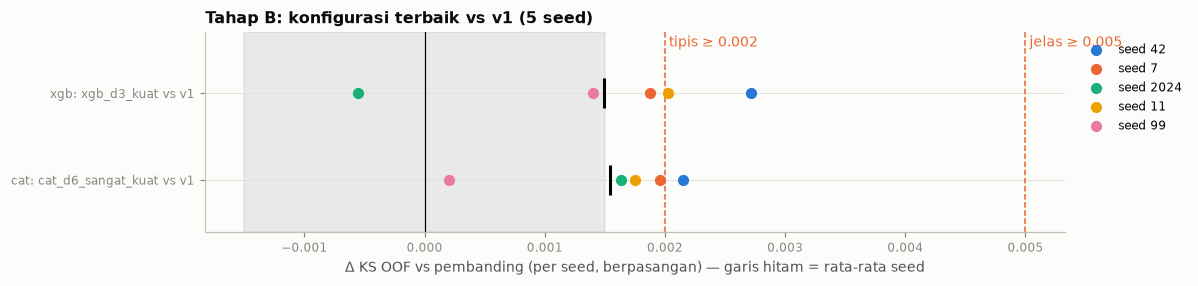

In [6]:
M.plot_paired_deltas({k: B[k]["cmp"] for k in B}, list(B), noise=0.0015,
                     labels=[f"{k}: {BEST_CFG[k]} vs v1" for k in B], title="Tahap B: konfigurasi terbaik vs v1 (5 seed)")

## 3. Tahap C: semua anggota sampai 10 seed

Seed yang sudah ada dipakai ulang, hanya seed yang kurang yang dilatih. Hasil gabungan disimpan sebagai run `*_s10` (bisa dipakai notebook lain).

In [7]:
def extend(member_name, kind, have, params=None):
    """Lengkapi run `have` sampai SEEDS_10 (hanya seed yang belum ada yang dilatih)."""
    missing = tuple(s for s in SEEDS_10 if s not in have["seeds"])
    parts = [have] + ([run_cached(f"{member_name}_ext10", kind, missing, params)] if missing else [])
    r = merge_runs(parts)
    r["oof_by_seed"] = {s: r["oof_by_seed"][s] for s in SEEDS_10}       # urutan seed konsisten
    r["seeds"] = list(SEEDS_10)
    M.save_run(f"{member_name}_s10", train, test, r, extra=dict(kind=kind, base=member_name))
    return r

S10 = {"lgbm": extend("lgbm_tuned", "lgbm", V1["lgbm"], P_LGB),
       "logreg": extend("logreg_v1", "logreg", V1["logreg"])}
for kind in ("xgb", "cat"):
    if CHOSEN[kind] == "v1":
        S10[kind] = extend(f"{kind}_v1", kind, B[kind]["v1"])
    else:
        name = CHOSEN[kind]
        S10[kind] = extend(f"t13_{name}", kind, B[kind]["tuned"], CONFIGS[name][1])
S10 = {k: S10[k] for k in ("lgbm", "xgb", "cat", "logreg")}
VERSI = {"lgbm": "lgbm_tuned", "xgb": CHOSEN["xgb"], "cat": CHOSEN["cat"], "logreg": "logreg_v1"}
pl.DataFrame([dict(anggota=k, versi=VERSI[k],
                   ks_rata2_per_seed=np.mean(list(r["ks_by_seed"].values())),
                   ks_oof_3_seed=M.ks_score(y, np.mean([r["oof_by_seed"][s] for s in SEEDS_A], axis=0)),
                   ks_oof_10_seed=r["ks_oof"]) for k, r in S10.items()]).with_columns(pl.col(pl.Float64).round(4))

  lgbm_tuned_ext10: seed [123, 2025, 31, 77, 555] selesai dalam 5.1 menit
  logreg_v1_ext10: seed [11, 99, 123, 2025, 31, 77, 555] selesai dalam 9.1 menit
  xgb_v1_ext10: seed [123, 2025, 31, 77, 555] selesai dalam 9.8 menit
  cat_v1_ext10: seed [123, 2025, 31, 77, 555] selesai dalam 35.2 menit


anggota,versi,ks_rata2_per_seed,ks_oof_3_seed,ks_oof_10_seed
str,str,f64,f64,f64
"""lgbm""","""lgbm_tuned""",0.5207,0.5238,0.5233
"""xgb""","""v1""",0.519,0.522,0.5226
"""cat""","""v1""",0.5185,0.5207,0.521
"""logreg""","""logreg_v1""",0.5179,0.5186,0.5186


## 4. Tahap D: ensemble

**(1) Efek tuning di tingkat ensemble**, berpasangan per seed di 5 seed (42, 7, 2024, 11, 99): ensemble dengan konfigurasi terbaik tahap A vs ensemble v1. Ini ditampilkan sebagai **informasi**, apa pun keputusan tahap B. Di ensemble, kenaikan satu anggota terbagi empat, jadi angkanya biasanya lebih kecil daripada di tingkat anggota.

**(2) Efek jumlah seed:** KS OOF gabungan ensemble untuk 1, 2, …, 10 seed. Kurva ini menunjukkan seberapa banyak manfaat perataan yang tersisa.

In [8]:
SEEDS_5 = list(SEEDS_A + SEEDS_B)
OLD5 = {"lgbm": S10["lgbm"], "xgb": B["xgb"]["v1"], "cat": B["cat"]["v1"], "logreg": S10["logreg"]}
ENS_OLD5 = M.blend(OLD5, y, seeds=SEEDS_5)
ENS_NEW5 = M.blend(S10, y, seeds=SEEDS_5)                    # versi terpilih (sama dengan v1 kalau tuning tidak lolos)
# informasi: ensemble dengan konfigurasi terbaik tahap A, terlepas dari keputusan per anggota
VARIANTS = {"XGB tuning saja": {**OLD5, "xgb": B["xgb"]["tuned"]},
            "CatBoost tuning saja": {**OLD5, "cat": B["cat"]["tuned"]},
            "XGB & CatBoost tuning": {**OLD5, "xgb": B["xgb"]["tuned"], "cat": B["cat"]["tuned"]}}
C_VAR = {n: M.compare_runs(ENS_OLD5, M.blend(v, y, seeds=SEEDS_5), y, SEG) for n, v in VARIANTS.items()}
print(f"Versi terpilih per anggota: {CHOSEN}  (tahap B)")
print("Ensemble dengan konfigurasi hasil tuning vs ensemble v1, 5 seed (informasi, berpasangan per seed):")
pl.DataFrame([cmp_row(f"ensemble, {n} vs v1", c) for n, c in C_VAR.items()]).with_columns(pl.col(pl.Float64).round(4))

Versi terpilih per anggota: {'xgb': 'v1', 'cat': 'v1'}  (tahap B)
Ensemble dengan konfigurasi hasil tuning vs ensemble v1, 5 seed (informasi, berpasangan per seed):


perbandingan,delta_oof_gabungan,d_s42,d_s7,d_s2024,d_s11,d_s99,delta_rata2,seed_naik,keputusan
str,f64,f64,f64,f64,f64,f64,f64,str,str
"""ensemble, XGB tuning saja vs v1""",-0.0001,0.0007,-0.0007,0.0001,0.0011,0.0,0.0002,"""4/5""","""tidak"""
"""ensemble, CatBoost tuning saja vs v1""",-0.0004,0.0005,-0.0017,0.001,-0.0005,-0.0003,-0.0002,"""2/5""","""tidak"""
"""ensemble, XGB & CatBoost tuning vs v1""",0.0001,0.001,-0.0016,0.0001,0.0009,-0.0009,-0.0001,"""3/5""","""tidak"""


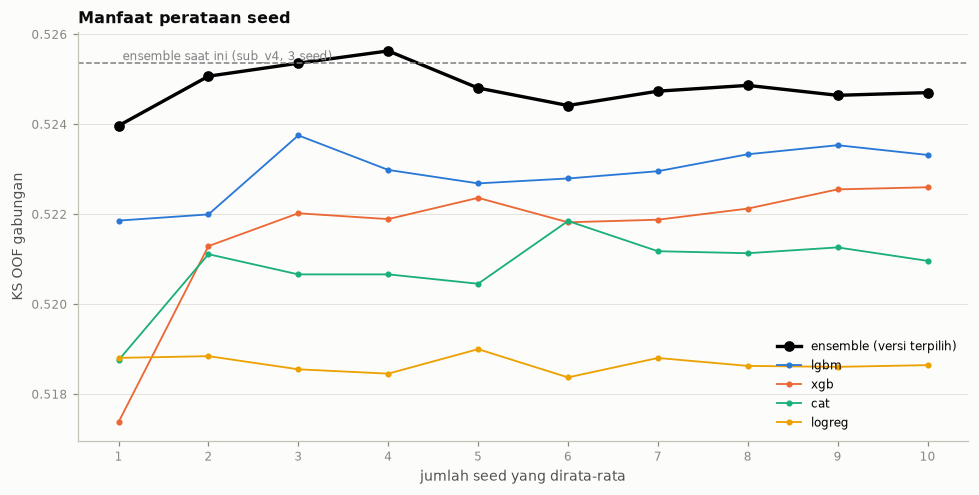

n_seed,ensemble_baru,lgbm,xgb,cat,logreg
i64,f64,f64,f64,f64,f64
1,0.524,0.5219,0.5174,0.5188,0.5188
2,0.5251,0.522,0.5213,0.5211,0.5188
3,0.5254,0.5238,0.522,0.5207,0.5186
4,0.5256,0.523,0.5219,0.5207,0.5185
5,0.5248,0.5227,0.5224,0.5205,0.519
6,0.5244,0.5228,0.5218,0.5218,0.5184
7,0.5247,0.523,0.5219,0.5212,0.5188
8,0.5249,0.5233,0.5221,0.5211,0.5186
9,0.5246,0.5235,0.5226,0.5213,0.5186


In [9]:
ENS_OLD3 = M.blend({k: V1[k] for k in V1}, y, seeds=list(SEEDS_A))    # ensemble saat ini (sub_v4), 3 seed
ENS_NEW10 = M.blend(S10, y, seeds=list(SEEDS_10))
curve = []
for k in range(1, len(SEEDS_10) + 1):
    ss = list(SEEDS_10[:k])
    curve.append(dict(n_seed=k, ensemble_baru=M.ks_score(y, np.mean([ENS_NEW10["oof_by_seed"][s] for s in ss], axis=0)),
                      **{m: M.ks_score(y, np.mean([S10[m]["oof_by_seed"][s] for s in ss], axis=0)) for m in S10}))
CURVE = pl.DataFrame(curve)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(CURVE["n_seed"], CURVE["ensemble_baru"], marker="o", lw=2.2, color="black", label="ensemble (versi terpilih)")
for j, m in enumerate(S10):
    ax.plot(CURVE["n_seed"], CURVE[m], marker=".", lw=1.2, color=E.SERIES[j % len(E.SERIES)], label=m)
ax.axhline(ENS_OLD3["ks_oof"], color="grey", ls="--", lw=1)
ax.text(1, ENS_OLD3["ks_oof"], " ensemble saat ini (sub_v4, 3 seed)", va="bottom", fontsize=8, color="grey")
ax.set_xticks(range(1, 11)); ax.set_xlabel("jumlah seed yang dirata-rata"); ax.set_ylabel("KS OOF gabungan")
ax.set_title("Manfaat perataan seed", loc="left"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
CURVE.with_columns(pl.col(pl.Float64).round(4))

In [10]:
summary = pl.DataFrame([
    dict(ensemble="saat ini (v1, 3 seed) — sub_v4", ks_oof_gabungan=ENS_OLD3["ks_oof"]),
    dict(ensemble="v1, 5 seed", ks_oof_gabungan=ENS_OLD5["ks_oof"]),
    dict(ensemble="XGB & CatBoost tuning, 5 seed (informasi)",
         ks_oof_gabungan=M.blend(VARIANTS["XGB & CatBoost tuning"], y, seeds=SEEDS_5)["ks_oof"]),
    dict(ensemble="versi terpilih, 5 seed", ks_oof_gabungan=ENS_NEW5["ks_oof"]),
    dict(ensemble="versi terpilih, 10 seed", ks_oof_gabungan=ENS_NEW10["ks_oof"]),
]).with_columns(delta_vs_saat_ini=pl.col("ks_oof_gabungan") - ENS_OLD3["ks_oof"])
summary.with_columns(pl.col(pl.Float64).round(4))

ensemble,ks_oof_gabungan,delta_vs_saat_ini
str,f64,f64
"""saat ini (v1, 3 seed) — sub_v4""",0.5254,0.0
"""v1, 5 seed""",0.5248,-0.0006
"""XGB & CatBoost tuning, 5 seed (informasi)""",0.5249,-0.0005
"""versi terpilih, 5 seed""",0.5248,-0.0006
"""versi terpilih, 10 seed""",0.5247,-0.0007


## 5. Submission

Ensemble versi terpilih dengan 10 seed. Tuning hanya masuk kalau lolos di tahap B; tambahan seed selalu dipakai karena secara teori tidak bisa merugikan. Prediksi test setiap anggota sekarang rata-rata **50 model** (10 seed × 5 fold), sebelumnya 15.

> Dari simulasi di notebook sebelumnya, selisih skor publik di bawah ± 0,005–0,008 antara dua submission belum tentu nyata. Patokan tetap OOF gabungan.

In [11]:
ENS_NEW10.update(features=[], params=ENS_NEW10.get("weights", {}), best_iters=[0])
M.save_run("ensemble_s10_v1", train, test, ENS_NEW10, extra=dict(members=VERSI,
                                                                   delta_vs_ensemble_v1=ENS_NEW10["ks_oof"] - ENS_OLD3["ks_oof"]))
ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
M.make_submission(test["application_id"], ENS_NEW10["test_pred"], ss, M.SUB_DIR / "sub_v6_ensemble_10seed.csv")
r = np.corrcoef(M.rank01(ENS_NEW10["test_pred"]), M.rank01(ENS_OLD3["test_pred"]))[0, 1]
print(f"Korelasi peringkat prediksi test vs ensemble saat ini (sub_v4): {r:.5f}")
if r > 0.999:
    print("→ Urutan prediksi test praktis identik dengan sub_v4. Submit file ini hanya memakai jatah tanpa informasi baru.")

✅ kolom tepat [application_id, default_probability]
✅ jumlah baris = sample_submission
✅ application_id unik
✅ semua ID test ada & tidak ada ID asing
✅ probabilitas finite
✅ probabilitas dalam [0, 1]
✅ prediksi tidak konstan
Tersimpan: d:\LOMBA\LOGIKA\submissions\sub_v6_ensemble_10seed.csv  (30,000 baris)
Korelasi peringkat prediksi test vs ensemble saat ini (sub_v4): 0.99996
→ Urutan prediksi test praktis identik dengan sub_v4. Submit file ini hanya memakai jatah tanpa informasi baru.
